# 03 · Limpieza, estructuración y preparación (Programación, Unidad 2)

| ID del enunciado | Qué cubre | Sección |
|---|---|---|
| **P2.1** / **P2.E1** | Identificar y manejar faltantes y duplicados; corregir tipos y valores inválidos | 1 |
| **P2.4** | Generar nuevas variables relevantes | 2 |
| **P2.6** / **P2.E4** | División train/test estratificada (antes de ajustar encoders y escaladores) | 3 |
| **P2.2** / **P2.E2** | One-Hot Encoding y Ordinal/Label Encoding | 4 |
| **P2.3** / **P2.E2** | Normalización (MinMax) y estandarización (Standard) | 5 |
| **P2.E3** | Selección de las características más relevantes | 6 |
| **P2.5** | Reducción de dimensionalidad (PCA) | 7 |
| — | Pipeline `ColumnTransformer` y exportación a `db/processed/` | 8, 9 |

El notebook es **autocontenido**: la lógica replica la de `Back/src/credit_risk/features.py` (misma fórmula de cuota) para que la API use el mismo preprocesamiento.

In [1]:
%matplotlib inline
import warnings
warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

def buscar_raiz(inicio: Path = Path.cwd()) -> Path:
    """Sube por los directorios hasta encontrar db/credit_risk.csv (rutas relativas, sin rutas absolutas)."""
    for carpeta in [inicio, *inicio.parents]:
        if (carpeta / "db" / "credit_risk.csv").exists():
            return carpeta
    raise FileNotFoundError("No se encontró db/credit_risk.csv; ejecute el notebook desde Back/notebooks/")

PROJECT_ROOT = buscar_raiz()
RAW_DATA_PATH = PROJECT_ROOT / "db" / "credit_risk.csv"      # equivalente a config.DATA_PATH
PROCESSED_DIR = PROJECT_ROOT / "db" / "processed"
TARGET, ID_COL, TEXT_COL = "default", "id_cliente", "texto_solicitud"

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 100, "axes.titleweight": "bold"})
pd.options.display.max_columns = 50
pd.options.display.width = 160
pd.options.display.float_format = "{:,.3f}".format
print("Raíz del proyecto (relativa al notebook):", Path("..", "..").as_posix())

Raíz del proyecto (relativa al notebook): ../..


In [2]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, OrdinalEncoder, MinMaxScaler, StandardScaler
from sklearn.feature_selection import mutual_info_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.decomposition import PCA
import json

df_raw = pd.read_csv(RAW_DATA_PATH)
df = df_raw.copy()
print("Dataset crudo:", df.shape)

Dataset crudo: (12144, 21)


## 1. P2.1 · Faltantes, duplicados, tipos y valores inválidos
### 1.1 Reporte de nulos

In [3]:
reporte_nulos = pd.DataFrame({"nulos": df.isna().sum(), "pct": (df.isna().mean() * 100).round(2)})
reporte_nulos = reporte_nulos.sort_values("nulos", ascending=False)
reporte_nulos[reporte_nulos["nulos"] > 0]

,nulos,pct
antiguedad_laboral_anios,1118,9.210
ingreso_mensual,749,6.170
relacion_deuda_ingreso,612,5.040
situacion_laboral,494,4.070
puntaje_buro,488,4.020
tipo_vivienda,387,3.190
texto_solicitud,240,1.980


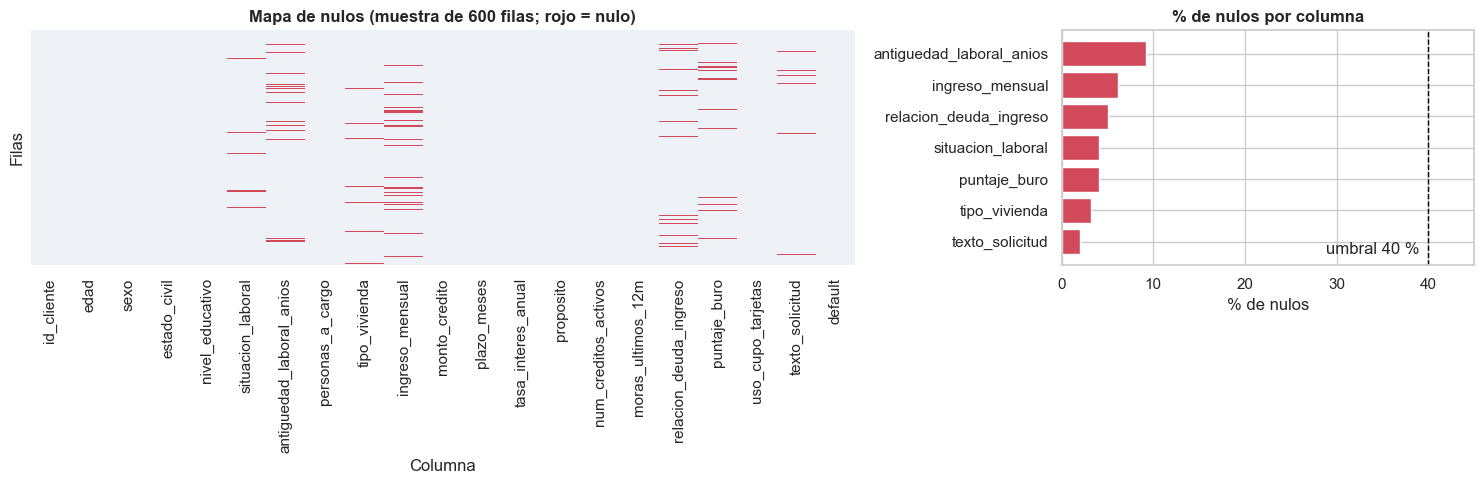

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
muestra = df.sample(600, random_state=RANDOM_STATE)
sns.heatmap(muestra.isna(), cbar=False, cmap=["#eef2f7", "#d1495b"], yticklabels=False, ax=axes[0])
axes[0].set_title("Mapa de nulos (muestra de 600 filas; rojo = nulo)"); axes[0].set_xlabel("Columna"); axes[0].set_ylabel("Filas")
con_nulos = reporte_nulos[reporte_nulos["nulos"] > 0]
axes[1].barh(con_nulos.index, con_nulos["pct"], color="#d1495b"); axes[1].invert_yaxis()
axes[1].axvline(40, ls="--", color="black", lw=1); axes[1].text(39, 6.4, "umbral 40 %", ha="right")
axes[1].set_title("% de nulos por columna"); axes[1].set_xlabel("% de nulos"); axes[1].set_xlim(0, 45)
plt.tight_layout(); plt.show()

**Interpretación:** los nulos están dispersos (no hay filas completamente vacías ni bloques) y **ninguna columna supera el 40 %** (máximo ≈ 9.2 % en `antiguedad_laboral_anios`), así que **no se elimina ninguna columna**; se imputan.

### 1.2 Duplicados

In [5]:
n0 = len(df)
dup_exactos = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
n1 = len(df)
dup_id = df[ID_COL].duplicated().sum()
df = df.drop_duplicates(subset=ID_COL, keep="first").reset_index(drop=True)
n2 = len(df)
print(f"Filas iniciales                 : {n0:,}")
print(f"Duplicados exactos eliminados   : {n0 - n1:,}")
print(f"Duplicados por ID eliminados    : {n1 - n2:,}")
print(f"Filas tras eliminar duplicados  : {n2:,}")
assert df.duplicated().sum() == 0 and df[ID_COL].is_unique

Filas iniciales                 : 12,144
Duplicados exactos eliminados   : 144
Duplicados por ID eliminados    : 0
Filas tras eliminar duplicados  : 12,000


### 1.3 Tipos y valores inválidos

In [6]:
# Categorías: normalizar espacios y mayúsculas para corregir categorías mal escritas
CATEGORIAS_VALIDAS = {
    "sexo": ["M", "F"],
    "estado_civil": ["Soltero", "Casado", "Union_libre", "Divorciado", "Viudo"],
    "nivel_educativo": ["Primaria", "Secundaria", "Tecnico", "Universitario", "Posgrado"],
    "situacion_laboral": ["Empleado", "Independiente", "Pensionado", "Desempleado"],
    "tipo_vivienda": ["Arriendo", "Propia", "Familiar"],
    "proposito": ["Libre_inversion", "Vehiculo", "Consolidacion_deuda", "Vivienda", "Negocio", "Educacion"],
}
for col, validas in CATEGORIAS_VALIDAS.items():
    mapa = {v.lower(): v for v in validas}
    limpio = df[col].astype("string").str.strip().str.replace(" ", "_").str.lower().map(mapa)
    invalidas = df[col].notna() & limpio.isna()
    print(f"{col:<18}: {invalidas.sum()} valores fuera de catálogo -> NaN | categorías: {sorted(limpio.dropna().unique())}")
    df[col] = limpio.astype(object)

# Edades fuera de 18-100 -> NaN (se imputan con la mediana)
edad_invalida = ~df["edad"].between(18, 100)
print(f"\nEdades inválidas: {edad_invalida.sum()} -> {sorted(df.loc[edad_invalida, 'edad'].unique())}")
df.loc[edad_invalida, "edad"] = np.nan

# Montos/ingresos negativos o cero -> NaN; rangos de las variables acotadas
for col in ["monto_credito", "ingreso_mensual"]:
    malos = df[col] <= 0
    print(f"{col}: {malos.sum()} valores <= 0 -> NaN")
    df.loc[malos, col] = np.nan
rangos = {"antiguedad_laboral_anios": (0, 70), "uso_cupo_tarjetas": (0, 1), "relacion_deuda_ingreso": (0, 1.5),
          "puntaje_buro": (150, 950), "tasa_interes_anual": (0, 100), "plazo_meses": (1, 120)}
for col, (lo, hi) in rangos.items():
    fuera = df[col].notna() & ~df[col].between(lo, hi)
    df.loc[fuera, col] = np.nan
    print(f"{col}: {fuera.sum()} fuera de [{lo}, {hi}]")

sexo              : 0 valores fuera de catálogo -> NaN | categorías: ['F', 'M']


estado_civil      : 0 valores fuera de catálogo -> NaN | categorías: ['Casado', 'Divorciado', 'Soltero', 'Union_libre', 'Viudo']


nivel_educativo   : 0 valores fuera de catálogo -> NaN | categorías: ['Posgrado', 'Primaria', 'Secundaria', 'Tecnico', 'Universitario']


situacion_laboral : 0 valores fuera de catálogo -> NaN | categorías: ['Desempleado', 'Empleado', 'Independiente', 'Pensionado']


tipo_vivienda     : 0 valores fuera de catálogo -> NaN | categorías: ['Arriendo', 'Familiar', 'Propia']


proposito         : 0 valores fuera de catálogo -> NaN | categorías: ['Consolidacion_deuda', 'Educacion', 'Libre_inversion', 'Negocio', 'Vehiculo', 'Vivienda']

Edades inválidas: 24 -> [1, 2, 120, 150, 999]
monto_credito: 0 valores <= 0 -> NaN
ingreso_mensual: 0 valores <= 0 -> NaN
antiguedad_laboral_anios: 0 fuera de [0, 70]
uso_cupo_tarjetas: 0 fuera de [0, 1]


relacion_deuda_ingreso: 0 fuera de [0, 1.5]
puntaje_buro: 0 fuera de [150, 950]
tasa_interes_anual: 0 fuera de [0, 100]
plazo_meses: 0 fuera de [1, 120]


### 1.4 Imputación sin fuga de información
Las estadísticas de imputación (mediana y moda) se calculan **solo con las filas que irán a entrenamiento**. Para eso se fija aquí la partición estratificada con los mismos parámetros que se usan en la sección 3 (`test_size=0.2`, `stratify=default`, `random_state=42`); al repetirla más adelante se obtiene exactamente la misma división (se verifica con un `assert`).

| Tipo | Estrategia | Justificación |
|---|---|---|
| Numéricas | **Mediana** de train | Robusta a la asimetría y a los atípicos de ingreso/monto |
| `situacion_laboral`, `tipo_vivienda` | Categoría **"Desconocido"** | La ausencia puede ser informativa (no declarar la situación laboral) y no se inventa un valor |
| Otras categóricas | **Moda** de train | No tienen nulos en el crudo; se deja como regla general |
| `texto_solicitud` | Marcador `"Sin texto"` | Un marcador explícito (y no una cadena vacía, que el CSV volvería a leer como nulo); `longitud_texto = 0` identifica estos casos |

In [7]:
idx_train_imp, _ = train_test_split(df.index, test_size=0.2, stratify=df[TARGET], random_state=RANDOM_STATE)
ref = df.loc[idx_train_imp]

num_cols_raw = ["edad", "antiguedad_laboral_anios", "personas_a_cargo", "ingreso_mensual", "monto_credito",
                "plazo_meses", "tasa_interes_anual", "num_creditos_activos", "moras_ultimos_12m",
                "relacion_deuda_ingreso", "puntaje_buro", "uso_cupo_tarjetas"]
cat_desconocido = ["situacion_laboral", "tipo_vivienda"]
cat_moda = [c for c in CATEGORIAS_VALIDAS if c not in cat_desconocido]

IMPUTACION = {"mediana": ref[num_cols_raw].median().round(4).to_dict(),
              "moda": {c: ref[c].mode().iloc[0] for c in cat_moda},
              "desconocido": {c: "Desconocido" for c in cat_desconocido}}
antes = df.isna().sum()
df[num_cols_raw] = df[num_cols_raw].fillna(IMPUTACION["mediana"])
df = df.fillna(IMPUTACION["moda"]).fillna(IMPUTACION["desconocido"])
TEXTO_FALTANTE = "Sin texto"
df[TEXT_COL] = df[TEXT_COL].fillna(TEXTO_FALTANTE)

# Tipos correctos
for c in ["edad", "personas_a_cargo", "plazo_meses", "num_creditos_activos", "moras_ultimos_12m", "puntaje_buro", TARGET]:
    df[c] = df[c].round().astype(int)

print(pd.DataFrame({"nulos_antes": antes, "nulos_despues": df.isna().sum()})[antes > 0])
print("\nMedianas usadas:", {k: round(v, 3) for k, v in IMPUTACION["mediana"].items() if antes[k] > 0})
assert df.isna().sum().sum() == 0

                          nulos_antes  nulos_despues
edad                               24              0
situacion_laboral                 485              0
antiguedad_laboral_anios         1104              0
tipo_vivienda                     380              0
ingreso_mensual                   739              0
relacion_deuda_ingreso            602              0
puntaje_buro                      479              0
texto_solicitud                   237              0

Medianas usadas: {'edad': 49.0, 'antiguedad_laboral_anios': 9.0, 'ingreso_mensual': 2234000.0, 'relacion_deuda_ingreso': 0.555, 'puntaje_buro': 715.0}


**Resultado P2.1:** se eliminaron los 144 duplicados exactos (los duplicados por ID coincidían con ellos, por lo que no quedó ningún ID repetido), las 24 edades imposibles que quedaban tras quitar duplicados se convirtieron en nulos y se imputaron, y **no queda ningún nulo**. Las categorías ya venían bien escritas, pero la normalización queda en el código para datos nuevos.

## 2. P2.4 · Nuevas variables

| Variable | Fórmula | Justificación de negocio |
|---|---|---|
| `cuota_estimada` | Amortización francesa: $M \cdot \frac{r}{1-(1+r)^{-n}}$ con $r$ = tasa anual/12 | Es lo que el cliente pagará cada mes; combina monto, tasa y plazo |
| `ratio_cuota_ingreso` | cuota / ingreso | **Capacidad de pago**: la regla bancaria clásica limita la cuota a ~30-40 % del ingreso |
| `ratio_monto_ingreso` | monto / ingreso | Endeudamiento relativo al tamaño del cliente |
| `rango_edad` | `cut` de edad en 18-25, 26-35, 36-45, 46-60, > 60 | Segmentos de ciclo de vida; además se usa para auditar equidad por edad |
| `tiene_moras_previas` | 1 si `moras_ultimos_12m` > 0 | Señal binaria de mal historial (el salto de 0 a 1 mora duplica el impago) |
| `longitud_texto` | nº de caracteres de `texto_solicitud` | Proxy simple del detalle de la solicitud; conecta con el NLP |

La fórmula de la cuota es la misma de `Back/src/credit_risk/features.py` (`crear_variables`).

In [8]:
def crear_variables(d: pd.DataFrame) -> pd.DataFrame:
    d = d.copy()
    r = d["tasa_interes_anual"] / 100 / 12
    n = d["plazo_meses"]
    d["cuota_estimada"] = np.where(r > 0, d["monto_credito"] * r / (1 - (1 + r) ** (-n)), d["monto_credito"] / n)
    d["ratio_cuota_ingreso"] = d["cuota_estimada"] / d["ingreso_mensual"]
    d["ratio_monto_ingreso"] = d["monto_credito"] / d["ingreso_mensual"]
    d["rango_edad"] = pd.cut(d["edad"], [17, 25, 35, 45, 60, 120],
                             labels=["18-25", "26-35", "36-45", "46-60", ">60"]).astype(str)
    d["tiene_moras_previas"] = (d["moras_ultimos_12m"] > 0).astype(int)
    d["longitud_texto"] = d[TEXT_COL].fillna("").replace("Sin texto", "").str.len()
    return d.replace([np.inf, -np.inf], np.nan)

df = crear_variables(df)
nuevas = ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso", "rango_edad", "tiene_moras_previas", "longitud_texto"]
assert df[nuevas].isna().sum().sum() == 0
df[nuevas + [TARGET]].head()

,cuota_estimada,ratio_cuota_ingreso,ratio_monto_ingreso,rango_edad,tiene_moras_previas,longitud_texto,default
0,"1,058,241.607",0.575,5.779,18-25,1,142,0
1,"711,205.703",0.180,3.754,>60,0,144,0
2,"684,651.117",0.577,3.322,>60,0,145,0
3,"317,495.143",0.269,6.281,26-35,1,191,1
4,"447,778.630",0.194,3.998,>60,0,142,0


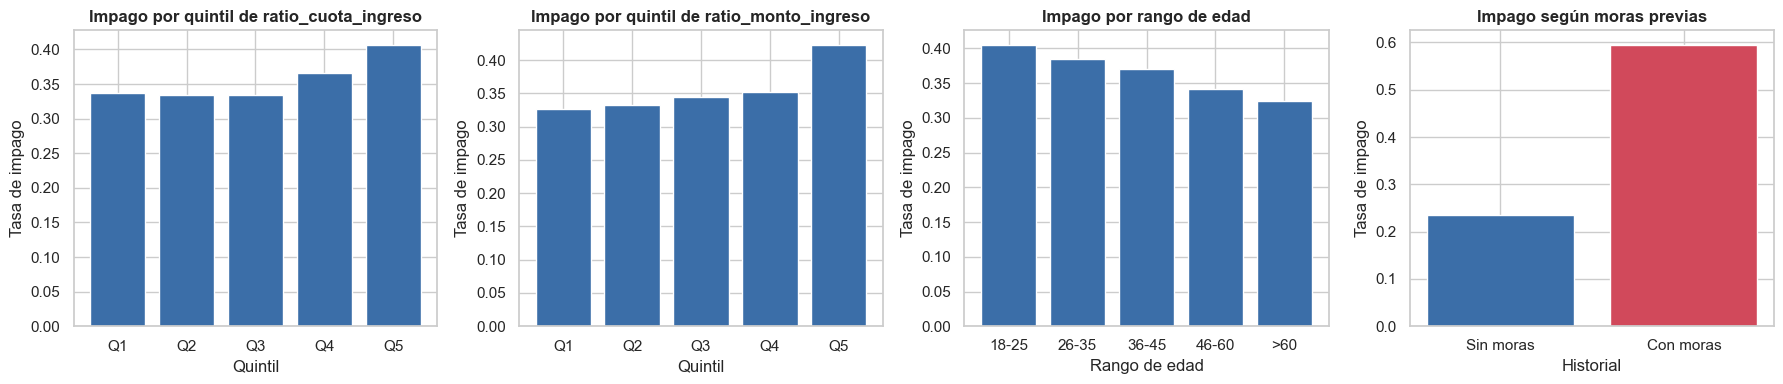

In [9]:
# ¿Aportan señal? Tasa de impago por quintil de cada ratio y por las nuevas categóricas
fig, axes = plt.subplots(1, 4, figsize=(18, 4))
for ax, col in zip(axes[:2], ["ratio_cuota_ingreso", "ratio_monto_ingreso"]):
    t = df.groupby(pd.qcut(df[col], 5, labels=["Q1", "Q2", "Q3", "Q4", "Q5"]), observed=True)[TARGET].mean()
    ax.bar(t.index.astype(str), t.values, color="#3b6ea8"); ax.set_title(f"Impago por quintil de {col}")
    ax.set_xlabel("Quintil"); ax.set_ylabel("Tasa de impago")
t = df.groupby("rango_edad")[TARGET].mean().reindex(["18-25", "26-35", "36-45", "46-60", ">60"])
axes[2].bar(t.index, t.values, color="#3b6ea8"); axes[2].set_title("Impago por rango de edad")
axes[2].set_xlabel("Rango de edad"); axes[2].set_ylabel("Tasa de impago")
t = df.groupby("tiene_moras_previas")[TARGET].mean()
axes[3].bar(["Sin moras", "Con moras"], t.values, color=["#3b6ea8", "#d1495b"]); axes[3].set_title("Impago según moras previas")
axes[3].set_xlabel("Historial"); axes[3].set_ylabel("Tasa de impago")
plt.tight_layout(); plt.show()

**Interpretación:** `tiene_moras_previas` separa con fuerza (≈ 23 % sin moras vs ≈ 60 % con moras) y el impago **baja con la edad** (≈ 42 % en 18-25 frente a ≈ 32 % en > 60); los ratios cuota/ingreso y monto/ingreso son planos en los primeros quintiles y suben en el **quintil más alto** (≈ 41-42 %), es decir, el riesgo aparece cuando la carga del crédito es claramente excesiva (la capacidad de pago también está parcialmente recogida por `relacion_deuda_ingreso`).

## 3. P2.6 · División train/test (antes de ajustar encoders y escaladores)
Se separa **antes** de ajustar cualquier codificador o escalador para evitar *data leakage*: todo `fit` se hace solo con train.

In [10]:
NOMINALES = ["estado_civil", "situacion_laboral", "tipo_vivienda", "proposito"]
ORDINALES = {"nivel_educativo": ["Primaria", "Secundaria", "Tecnico", "Universitario", "Posgrado"],
             "rango_edad": ["18-25", "26-35", "36-45", "46-60", ">60"]}
NUMERICAS = num_cols_raw + ["cuota_estimada", "ratio_cuota_ingreso", "ratio_monto_ingreso",
                            "tiene_moras_previas", "longitud_texto"]
EXCLUIDAS = [ID_COL, "sexo", TEXT_COL]   # id: identificador; sexo: solo auditoría; texto: va al NLP (paso 7)

X = df.drop(columns=[TARGET])
y = df[TARGET]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)
assert set(X_train.index) == set(idx_train_imp), "La partición debe coincidir con la usada para imputar"

resumen = pd.DataFrame({"filas": [len(y), len(y_train), len(y_test)],
                        "tasa_default": [y.mean(), y_train.mean(), y_test.mean()]},
                       index=["Total", "Train (80 %)", "Test (20 %)"])
resumen

,filas,tasa_default
Total,12000,0.356
Train (80 %),9600,0.356
Test (20 %),2400,0.356


**Interpretación:** la estratificación conserva la misma tasa de impago (≈ 35.6 %) en train y test, por lo que las métricas de test serán representativas.

## 4. P2.2 · Codificación de variables categóricas
- **One-Hot** para las nominales (sin orden natural): `estado_civil`, `situacion_laboral`, `tipo_vivienda`, `proposito`. `handle_unknown="ignore"` evita errores con categorías nuevas en producción.
- **Ordinal (Label) Encoding** para las ordinales, respetando su orden: `nivel_educativo` y `rango_edad`.

In [11]:
ohe = OneHotEncoder(handle_unknown="ignore", sparse_output=False)
ohe.fit(X_train[NOMINALES])
ohe_train = pd.DataFrame(ohe.transform(X_train[NOMINALES]), columns=ohe.get_feature_names_out(), index=X_train.index)
print(f"One-Hot: {len(NOMINALES)} columnas nominales -> {ohe_train.shape[1]} columnas binarias")
pd.concat([X_train[NOMINALES].head(3), ohe_train.head(3)], axis=1)

One-Hot: 4 columnas nominales -> 20 columnas binarias


,estado_civil,situacion_laboral,tipo_vivienda,proposito,estado_civil_Casado,estado_civil_Divorciado,estado_civil_Soltero,estado_civil_Union_libre,estado_civil_Viudo,situacion_laboral_Desconocido,situacion_laboral_Desempleado,situacion_laboral_Empleado,situacion_laboral_Independiente,situacion_laboral_Pensionado,tipo_vivienda_Arriendo,tipo_vivienda_Desconocido,tipo_vivienda_Familiar,tipo_vivienda_Propia,proposito_Consolidacion_deuda,proposito_Educacion,proposito_Libre_inversion,proposito_Negocio,proposito_Vehiculo,proposito_Vivienda
7052,Union_libre,Pensionado,Propia,Vivienda,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000
225,Casado,Independiente,Propia,Vivienda,1.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000
9819,Soltero,Empleado,Propia,Vehiculo,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,0.000,1.000,0.000,0.000,0.000,0.000,1.000,0.000


In [12]:
ord_enc = OrdinalEncoder(categories=[ORDINALES[c] for c in ORDINALES], handle_unknown="use_encoded_value", unknown_value=-1)
ord_enc.fit(X_train[list(ORDINALES)])
for col, cats in zip(ORDINALES, ord_enc.categories_):
    print(f"Mapeo {col}: " + ", ".join(f"{c} -> {i}" for i, c in enumerate(cats)))
ord_train = pd.DataFrame(ord_enc.transform(X_train[list(ORDINALES)]), columns=[f"{c}_ord" for c in ORDINALES], index=X_train.index)
pd.concat([X_train[list(ORDINALES)].head(), ord_train.head()], axis=1)

Mapeo nivel_educativo: Primaria -> 0, Secundaria -> 1, Tecnico -> 2, Universitario -> 3, Posgrado -> 4
Mapeo rango_edad: 18-25 -> 0, 26-35 -> 1, 36-45 -> 2, 46-60 -> 3, >60 -> 4


,nivel_educativo,rango_edad,nivel_educativo_ord,rango_edad_ord
7052,Secundaria,26-35,1.000,1.000
225,Tecnico,18-25,2.000,0.000
9819,Primaria,46-60,0.000,3.000
2902,Tecnico,46-60,2.000,3.000
4040,Secundaria,>60,1.000,4.000


## 5. P2.3 · Normalización y estandarización
Se comparan ambas técnicas sobre las variables numéricas (ajustadas solo con train).

In [13]:
mm = MinMaxScaler().fit(X_train[NUMERICAS])
ss = StandardScaler().fit(X_train[NUMERICAS])
X_mm = pd.DataFrame(mm.transform(X_train[NUMERICAS]), columns=NUMERICAS, index=X_train.index)
X_ss = pd.DataFrame(ss.transform(X_train[NUMERICAS]), columns=NUMERICAS, index=X_train.index)
comp = pd.concat({"original": X_train[NUMERICAS].describe().T[["mean", "std", "min", "max"]],
                  "MinMax": X_mm.describe().T[["mean", "std", "min", "max"]],
                  "Standard": X_ss.describe().T[["mean", "std", "min", "max"]]}, axis=1)
comp.loc[["edad", "ingreso_mensual", "monto_credito", "puntaje_buro", "uso_cupo_tarjetas"]].round(3)

original                                                MinMax                   Standard                    
                            mean            std           min               max   mean   std   min   max     mean   std    min    max
edad                      48.936         18.084        18.000            80.000  0.499 0.292 0.000 1.000   -0.000 1.000 -1.711  1.718
ingreso_mensual    2,595,665.625  1,968,014.814   312,000.000    64,540,000.000  0.036 0.031 0.000 1.000    0.000 1.000 -1.160 31.477
monto_credito     21,659,643.958 32,184,295.013 1,000,000.000 1,033,300,000.000  0.020 0.031 0.000 1.000    0.000 1.000 -0.642 31.434
puntaje_buro             708.763        116.103       150.000           950.000  0.698 0.145 0.000 1.000    0.000 1.000 -4.813  2.078
uso_cupo_tarjetas          0.455          0.251         0.000             1.000  0.455 0.251 0.000 1.000   -0.000 1.000 -1.808  2.168

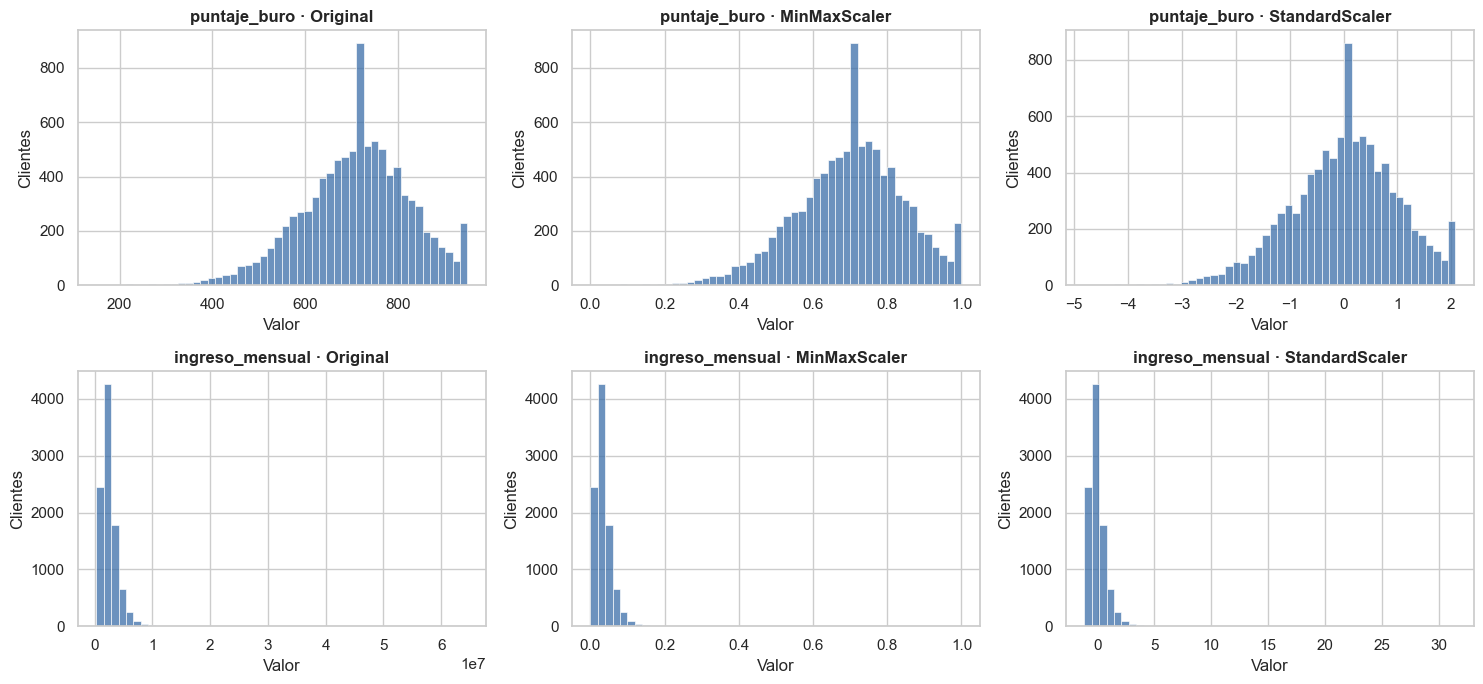

In [14]:
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for fila, col in enumerate(["puntaje_buro", "ingreso_mensual"]):
    for ax, (nombre, datos) in zip(axes[fila], [("Original", X_train[col]), ("MinMaxScaler", X_mm[col]), ("StandardScaler", X_ss[col])]):
        sns.histplot(datos, bins=50, ax=ax, color="#3b6ea8")
        ax.set_title(f"{col} · {nombre}"); ax.set_xlabel("Valor"); ax.set_ylabel("Clientes")
plt.tight_layout(); plt.show()

**Interpretación y decisión:** ambas técnicas conservan la **forma** de la distribución y solo cambian la escala. `MinMaxScaler` lleva todo a [0, 1], pero con atípicos extremos (ingreso con un cero de más) **comprime casi todos los valores cerca de 0**, como se ve en el histograma del ingreso. `StandardScaler` (media 0, desviación 1) es menos sensible a ese efecto y es la escala natural para la regresión logística regularizada, las redes neuronales y el PCA. **Se elige `StandardScaler` para el pipeline.**

## 6. P2.E3 · Selección de características
Tres criterios calculados **solo con train**: correlación (Spearman) con el objetivo, información mutua y la importancia de un árbol base (Random Forest pequeño, más estable que un solo árbol).

In [15]:
def build_preprocessor(numericas=NUMERICAS, nominales=NOMINALES, ordinales=ORDINALES):
    """Réplica autocontenida de features.build_preprocessor(): imputación + escalado + codificación."""
    num = Pipeline([("imputer", SimpleImputer(strategy="median")), ("scaler", StandardScaler())])
    nom = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                    ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])
    orde = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("ordinal", OrdinalEncoder(categories=[ordinales[c] for c in ordinales],
                                                handle_unknown="use_encoded_value", unknown_value=-1))])
    return ColumnTransformer([("num", num, numericas), ("nom", nom, nominales), ("ord", orde, list(ordinales))],
                             verbose_feature_names_out=False)

pre = build_preprocessor().fit(X_train)
Xt_train = pd.DataFrame(pre.transform(X_train), columns=pre.get_feature_names_out(), index=X_train.index)
Xt_test = pd.DataFrame(pre.transform(X_test), columns=pre.get_feature_names_out(), index=X_test.index)
print("Matriz transformada de train:", Xt_train.shape, "| test:", Xt_test.shape)

Matriz transformada de train: (9600, 39) | test: (2400, 39)


In [16]:
# Correlación de Spearman con el objetivo (numéricas + ordinales codificadas)
corr = Xt_train.corrwith(y_train, method="spearman")
# Información mutua
mi = pd.Series(mutual_info_classif(Xt_train, y_train, random_state=RANDOM_STATE,
                                   discrete_features=[c not in NUMERICAS or c == "tiene_moras_previas" for c in Xt_train.columns]),
               index=Xt_train.columns)
# Importancia de un árbol base
rf = RandomForestClassifier(n_estimators=200, max_depth=8, random_state=RANDOM_STATE, n_jobs=-1).fit(Xt_train, y_train)
imp = pd.Series(rf.feature_importances_, index=Xt_train.columns)

# Agregar por variable original (las dummies del One-Hot suman su aporte)
def original(col):
    for c in NOMINALES:
        if col.startswith(c + "_"):
            return c
    return col
tabla = pd.DataFrame({"abs_corr_spearman": corr.abs(), "info_mutua": mi, "importancia_rf": imp})
tabla["variable"] = [original(c) for c in tabla.index]
sel = tabla.groupby("variable").agg(abs_corr_spearman=("abs_corr_spearman", "max"), info_mutua=("info_mutua", "sum"),
                                    importancia_rf=("importancia_rf", "sum"))
for c in ["abs_corr_spearman", "info_mutua", "importancia_rf"]:
    sel[f"rank_{c}"] = sel[c].rank(ascending=False)
sel["rank_promedio"] = sel[[c for c in sel.columns if c.startswith("rank_")]].mean(axis=1)
sel = sel.sort_values("rank_promedio")

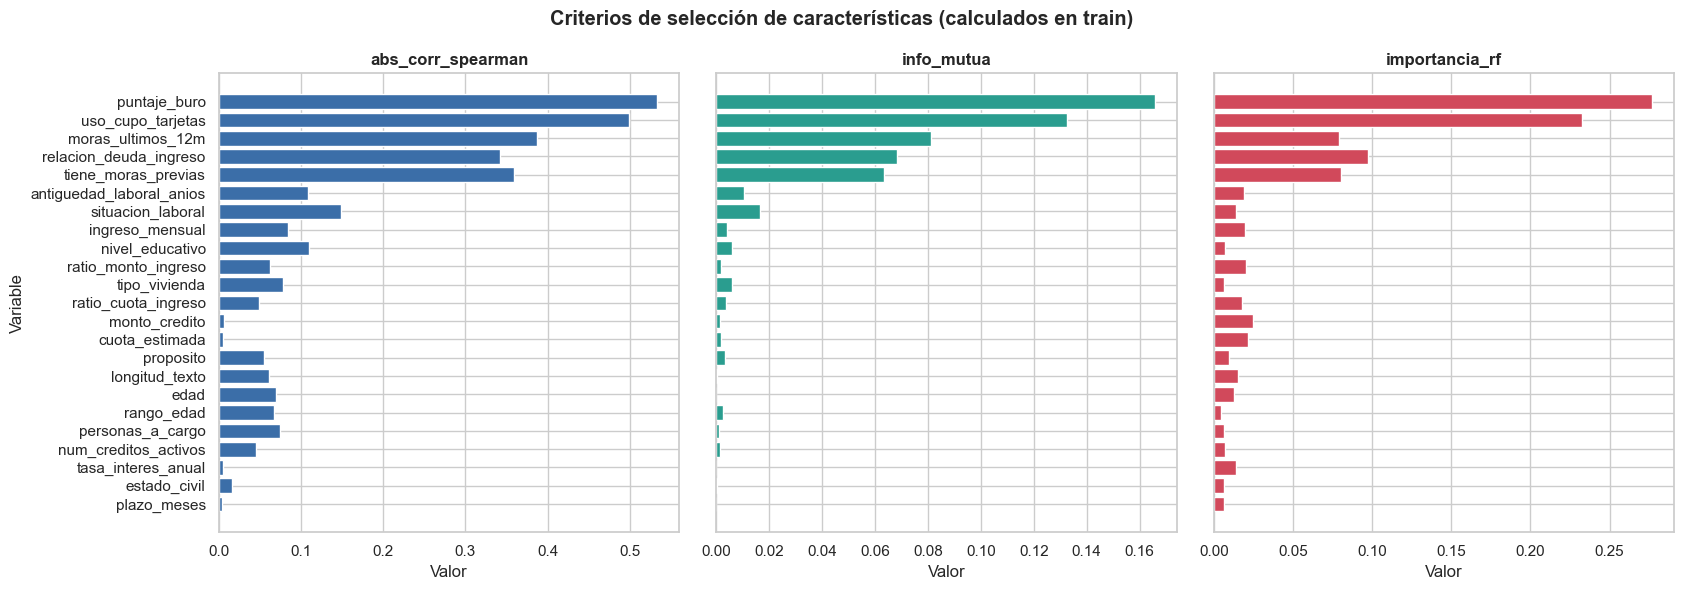

In [17]:
fig, axes = plt.subplots(1, 3, figsize=(17, 6), sharey=True)
orden = sel.index[::-1]
for ax, c, color in zip(axes, ["abs_corr_spearman", "info_mutua", "importancia_rf"], ["#3b6ea8", "#2a9d8f", "#d1495b"]):
    ax.barh(orden, sel.loc[orden, c], color=color); ax.set_title(c); ax.set_xlabel("Valor")
axes[0].set_ylabel("Variable")
plt.suptitle("Criterios de selección de características (calculados en train)", fontweight="bold")
plt.tight_layout(); plt.show()

**Regla de selección:** se **conserva** una variable si cumple al menos uno de estos criterios: |correlación| ≥ 0.02, información mutua ≥ 0.001 o importancia en el árbol ≥ 0.5 %; las que no cumplan ninguno se descartan por no aportar señal. `sexo` está excluida desde antes por ética. (Resultado: las 23 variables candidatas superan al menos un criterio; `plazo_meses`, `tasa_interes_anual` y `estado_civil` quedan al final del ranking y entran solo por la importancia del árbol, es decir, por posibles interacciones. Se conservan y se revisarán con la importancia por permutación del paso 5.)

In [18]:
sel["seleccionada"] = (sel["abs_corr_spearman"] >= 0.02) | (sel["info_mutua"] >= 0.001) | (sel["importancia_rf"] >= 0.005)
SELECCIONADAS = sel.index[sel["seleccionada"]].tolist()
DESCARTADAS = sel.index[~sel["seleccionada"]].tolist()
print(f"Seleccionadas ({len(SELECCIONADAS)}):", SELECCIONADAS)
print(f"Descartadas   ({len(DESCARTADAS)}):", DESCARTADAS)
sel.round(4)

Seleccionadas (23): ['puntaje_buro', 'uso_cupo_tarjetas', 'moras_ultimos_12m', 'relacion_deuda_ingreso', 'tiene_moras_previas', 'antiguedad_laboral_anios', 'situacion_laboral', 'ingreso_mensual', 'nivel_educativo', 'ratio_monto_ingreso', 'tipo_vivienda', 'ratio_cuota_ingreso', 'monto_credito', 'cuota_estimada', 'proposito', 'longitud_texto', 'edad', 'rango_edad', 'personas_a_cargo', 'num_creditos_activos', 'tasa_interes_anual', 'estado_civil', 'plazo_meses']
Descartadas   (0): []


,abs_corr_spearman,info_mutua,importancia_rf,rank_abs_corr_spearman,rank_info_mutua,rank_importancia_rf,rank_promedio,seleccionada
variable,,,,,,,,
puntaje_buro,0.533,0.166,0.277,1.000,1.000,1.000,1.000,True
uso_cupo_tarjetas,0.499,0.133,0.232,2.000,2.000,2.000,2.000,True
moras_ultimos_12m,0.387,0.081,0.079,3.000,3.000,5.000,3.667,True
relacion_deuda_ingreso,0.342,0.068,0.098,5.000,4.000,3.000,4.000,True
tiene_moras_previas,0.359,0.064,0.080,4.000,5.000,4.000,4.333,True
antiguedad_laboral_anios,0.108,0.011,0.019,8.000,7.000,10.000,8.333,True
situacion_laboral,0.149,0.017,0.014,6.000,6.000,14.000,8.667,True
ingreso_mensual,0.084,0.004,0.020,9.000,10.000,9.000,9.333,True
nivel_educativo,0.109,0.006,0.007,7.000,8.000,18.000,11.000,True


## 7. P2.5 · Reducción de dimensionalidad (PCA)
Regla de decisión del plan: **si se necesitan menos del 90 % de las componentes para explicar el 95 % de la varianza**, PCA comprime de forma útil y se documenta; si no, se justifica no usarlo.

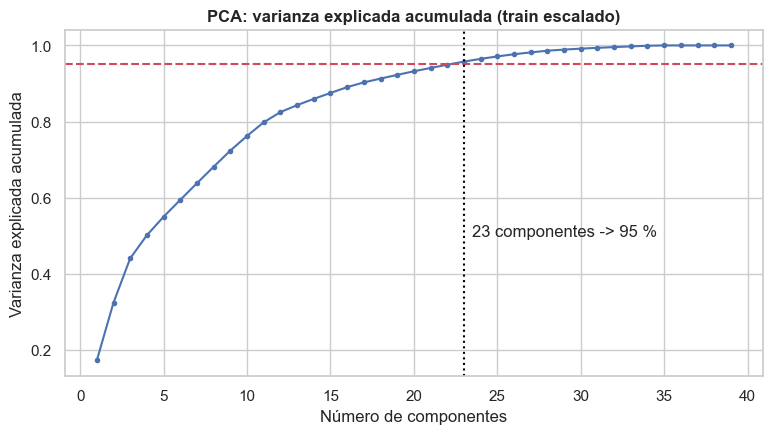

Componentes totales: 39 | para 95 % de varianza: 23 (59% del total)
Decisión: PCA comprime de forma útil (se documenta como opción)


In [19]:
pca = PCA(random_state=RANDOM_STATE).fit(Xt_train)
var_acum = np.cumsum(pca.explained_variance_ratio_)
n_total = Xt_train.shape[1]
n_95 = int(np.argmax(var_acum >= 0.95) + 1)

fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(range(1, n_total + 1), var_acum, marker="o", ms=3)
ax.axhline(0.95, ls="--", color="#d1495b"); ax.axvline(n_95, ls=":", color="black")
ax.set_title("PCA: varianza explicada acumulada (train escalado)")
ax.set_xlabel("Número de componentes"); ax.set_ylabel("Varianza explicada acumulada")
ax.text(n_95 + 0.5, 0.5, f"{n_95} componentes -> 95 %"); plt.show()

usa_pca = n_95 < 0.9 * n_total
print(f"Componentes totales: {n_total} | para 95 % de varianza: {n_95} ({n_95/n_total:.0%} del total)")
print("Decisión:", "PCA comprime de forma útil (se documenta como opción)" if usa_pca else "PCA no compensa")

**Decisión sobre PCA:** se necesitan **23 de 39 componentes (59 %)** para explicar el 95 % de la varianza; según la regla del plan, la compresión es posible y queda **documentada**. Aun así, **no se usa en el pipeline principal** porque: (1) el número de variables (~35 tras la codificación) es bajo para ~9.6 mil filas, no hay problema de dimensionalidad; (2) las componentes son combinaciones lineales difíciles de explicar al analista y al regulador, lo que va contra la explicabilidad exigida en el análisis ético; (3) los modelos de árbol no lo necesitan. PCA se mantiene como herramienta de **visualización** (notebook 04) y como opción para las redes neuronales.

## 8. Pipeline final (`ColumnTransformer`)
El preprocesador combina imputación (red de seguridad para datos nuevos de la API), `StandardScaler` en numéricas, One-Hot en nominales y Ordinal en ordinales, **restringido a las variables seleccionadas**. Se ajusta **solo con train**.

In [20]:
NUM_SEL = [c for c in NUMERICAS if c in SELECCIONADAS]
NOM_SEL = [c for c in NOMINALES if c in SELECCIONADAS]
ORD_SEL = {c: v for c, v in ORDINALES.items() if c in SELECCIONADAS}
preprocesador = build_preprocessor(NUM_SEL, NOM_SEL, ORD_SEL).fit(X_train)
print(preprocesador)
print("\nSalida del preprocesador:", preprocesador.transform(X_train).shape[1], "columnas")

# Comprobación rápida de utilidad: regresión logística sobre el pipeline (solo informativa)
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score
pipe = Pipeline([("pre", build_preprocessor(NUM_SEL, NOM_SEL, ORD_SEL)),
                 ("lr", LogisticRegression(max_iter=1000, class_weight="balanced"))]).fit(X_train, y_train)
print(f"AUC de verificación (LogReg, test): {roc_auc_score(y_test, pipe.predict_proba(X_test)[:, 1]):.3f}")

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['edad', 'antiguedad_laboral_anios',
                                  'personas_a_cargo', 'ingreso_mensual',
                                  'monto_credito', 'plazo_meses',
                                  'tasa_interes_anual', 'num_creditos_activos',
                                  'moras_ultimos_12m', 'relacion_deuda_ingreso',
                                  'puntaje_buro', 'uso_cupo_tarj...
                                  'tipo_vivienda', 'proposito']),
                                ('ord',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                    


Salida del preprocesador: 39 columnas


AUC de verificación (LogReg, test): 0.847


## 9. Exportación a `db/processed/`
Se guardan `train.csv` y `test.csv` **limpios y sin escalar** (con el objetivo, el texto y `sexo` para la auditoría de equidad), y `feature_list.json` con la definición de las variables.

In [21]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
train_out = X_train.assign(**{TARGET: y_train}).sort_index()
test_out = X_test.assign(**{TARGET: y_test}).sort_index()
for nombre, d in {"train": train_out, "test": test_out}.items():
    assert d.isna().sum().sum() == 0 and not d.duplicated().any(), f"{nombre} tiene nulos o duplicados"
train_out.to_csv(PROCESSED_DIR / "train.csv", index=False)
test_out.to_csv(PROCESSED_DIR / "test.csv", index=False)

feature_list = {
    "target": TARGET,
    "id": ID_COL,
    "texto": TEXT_COL,
    "random_state": RANDOM_STATE,
    "test_size": 0.2,
    "numericas": NUM_SEL,
    "nominales_onehot": NOM_SEL,
    "ordinales": ORD_SEL,
    "features_modelo": NUM_SEL + NOM_SEL + list(ORD_SEL),
    "descartadas_por_seleccion": DESCARTADAS,
    "excluidas": {"id_cliente": "identificador", "sexo": "variable sensible: solo auditoría de equidad",
                  "texto_solicitud": "se modela en el paso 7 (NLP)"},
    "variables_sensibles_auditoria": ["sexo", "edad", "rango_edad", "estado_civil"],
    "nuevas_variables": nuevas,
    "escalador": "StandardScaler",
    "imputacion": IMPUTACION,
    "pca": {"usado": False, "componentes_95pct": n_95, "componentes_totales": n_total},
    "filas": {"train": len(train_out), "test": len(test_out)},
    "tasa_default": {"train": round(float(y_train.mean()), 4), "test": round(float(y_test.mean()), 4)},
}
with open(PROCESSED_DIR / "feature_list.json", "w", encoding="utf-8") as f:
    json.dump(feature_list, f, ensure_ascii=False, indent=2, default=float)

for p in ["train.csv", "test.csv", "feature_list.json"]:
    print(f"{p:<18} -> {(PROCESSED_DIR / p).relative_to(PROJECT_ROOT).as_posix()} ({(PROCESSED_DIR / p).stat().st_size/1024:,.0f} KB)")
print("train:", train_out.shape, "| test:", test_out.shape)

train.csv          -> db/processed/train.csv (2,962 KB)
test.csv           -> db/processed/test.csv (740 KB)
feature_list.json  -> db/processed/feature_list.json (3 KB)
train: (9600, 27) | test: (2400, 27)


## Conclusiones

- **P2.1 / P2.E1:** se eliminaron **144 duplicados exactos** (eran también los IDs repetidos), quedando **12 000 clientes únicos**; se corrigieron **24 edades imposibles** (1, 2, 120, 150, 999; eran 25 en el crudo, una estaba en una fila duplicada) y se imputaron los nulos de 7 columnas (mediana de train en numéricas, "Desconocido" en situación laboral y tipo de vivienda, marcador "Sin texto" en `texto_solicitud`). Ninguna columna superó el 40 % de nulos. Los datos exportados **no tienen nulos ni duplicados**.
- **P2.4:** se crearon 6 variables con justificación de negocio (`cuota_estimada`, `ratio_cuota_ingreso`, `ratio_monto_ingreso`, `rango_edad`, `tiene_moras_previas`, `longitud_texto`); `tiene_moras_previas` es la más discriminante (≈ 23 % vs ≈ 60 % de impago).
- **P2.6 / P2.E4:** división estratificada 80/20 (`random_state=42`) **antes** de ajustar escaladores y encoders; la tasa de default se mantiene en ≈ 35.6 % en ambos conjuntos.
- **P2.2 / P2.3 / P2.E2:** One-Hot en 4 nominales, Ordinal en `nivel_educativo` y `rango_edad` (con su mapeo); se compararon MinMax y Standard y se eligió **StandardScaler** por su menor sensibilidad a los atípicos.
- **P2.E3:** según correlación, información mutua e importancia del árbol, las variables más relevantes son `puntaje_buro`, `uso_cupo_tarjetas`, `moras_ultimos_12m` / `tiene_moras_previas`, `relacion_deuda_ingreso` y `situacion_laboral`; las 23 candidatas superan al menos un criterio y quedan en `feature_list.json` (17 numéricas, 4 nominales con One-Hot y 2 ordinales). Una regresión logística de verificación sobre este pipeline obtiene **AUC ≈ 0.85 en test**, por encima de la meta de 0.70.
- **P2.5:** PCA necesita 23 de 39 componentes para el 95 % de la varianza; se documenta, pero **no se usa** en el pipeline principal por explicabilidad y baja dimensionalidad.
- Entregables: `db/processed/train.csv`, `db/processed/test.csv` y `db/processed/feature_list.json`, listos para los modelos del paso 5.